# Distance Ratio vs Pooling Benefit

Does the ratio between own-R1 distance and neighbor-R1 distance predict
whether pooling helps? Extended distance ranges: same_bn 10-40, inter_bn 15-70.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

RESULTS_PATH = _root / "data_cluster" / "resource_grid" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
df = df[df["n_amb_r1_to_ccp"] == 2].reset_index(drop=True)
print(f"Loaded {len(df)} runs (filtered n_amb==2)")

stove = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
both  = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
assert (stove["scenario"].values == both["scenario"].values).all()
print(f"Matched scenarios: {len(stove)}")

In [2]:
distance_ratio = stove["ccp_r1_same_bn_min"].values / stove["ccp_r1_inter_bn_min"].values
benefit = stove["death_rate_T1_BCAS"].values - both["death_rate_T1_BCAS"].values

result = pd.DataFrame({
    "distance_ratio": distance_ratio,
    "benefit": benefit,
    "same_bn": stove["ccp_r1_same_bn_min"].values,
    "inter_bn": stove["ccp_r1_inter_bn_min"].values,
    "bcas_rate": stove["bcas_rate"].values,
    "waves_per_day": stove["waves_per_day"].values,
})

print(f"Distance ratio: min={distance_ratio.min():.3f}, max={distance_ratio.max():.3f}, median={np.median(distance_ratio):.3f}")
print(f"Benefit (stove - both): min={benefit.min():.3f}, max={benefit.max():.3f}, median={np.median(benefit):.3f}")
print(f"Cases where pooling helps: {(benefit > 0.01).sum()} ({(benefit > 0.01).mean():.1%})")
print(f"Cases where pooling hurts: {(benefit < -0.01).sum()} ({(benefit < -0.01).mean():.1%})")

Distance ratio: min=0.143, max=2.667, median=0.588
Benefit (stove - both): min=-0.750, max=1.000, median=0.300
Cases where pooling helps: 19566 (79.6%)
Cases where pooling hurts: 1203 (4.9%)


## Scatter: Distance Ratio vs Pooling Benefit

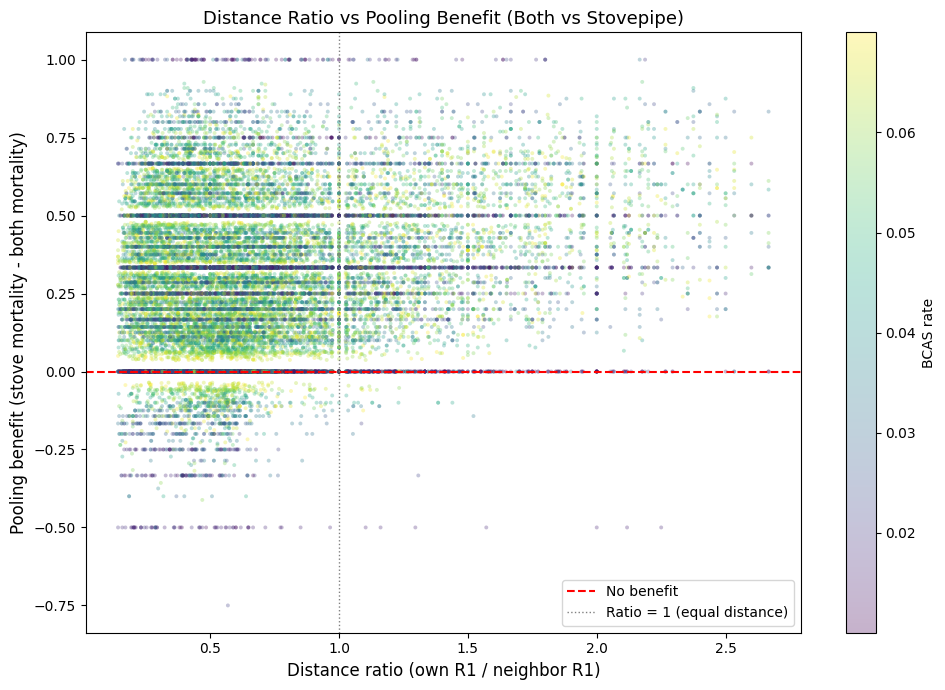

In [3]:
fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(distance_ratio, benefit, c=result["bcas_rate"], cmap="viridis",
                alpha=0.3, s=8, edgecolors="none")
ax.axhline(0, color="red", linewidth=1.5, linestyle="--", label="No benefit")
ax.axvline(1, color="grey", linewidth=1, linestyle=":", label="Ratio = 1 (equal distance)")
ax.set_xlabel("Distance ratio (own R1 / neighbor R1)", fontsize=12)
ax.set_ylabel("Pooling benefit (stove mortality - both mortality)", fontsize=12)
ax.set_title("Distance Ratio vs Pooling Benefit (Both vs Stovepipe)", fontsize=13)
plt.colorbar(sc, ax=ax, label="BCAS rate")
ax.legend()
plt.tight_layout()
plt.show()

## Binned: Mean Benefit by Distance Ratio Bin

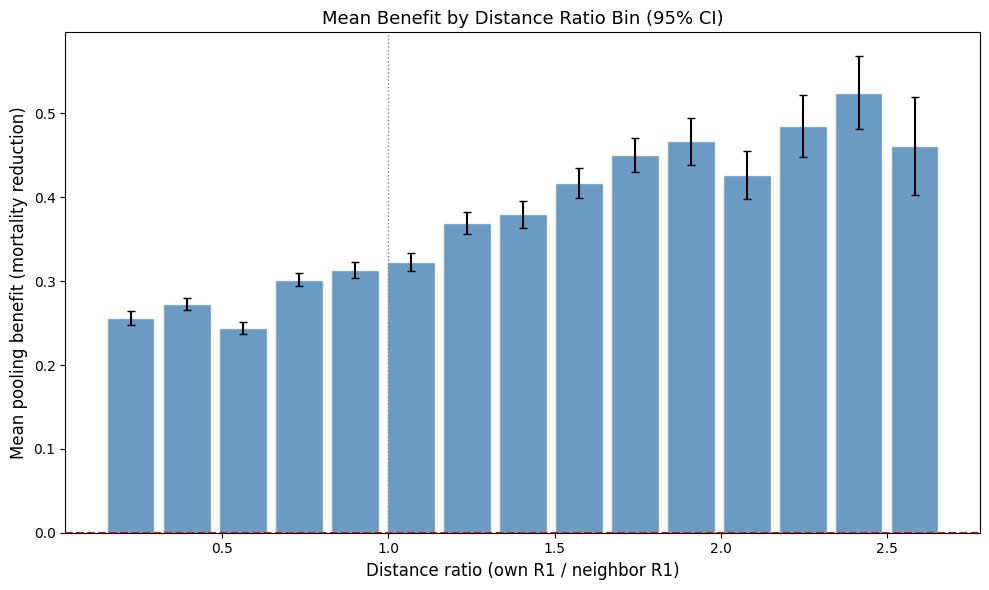

In [4]:
result["ratio_bin"] = pd.cut(result["distance_ratio"], bins=15)
binned = result.groupby("ratio_bin", observed=True)["benefit"].agg(["mean", "std", "count"])
binned["se"] = binned["std"] / np.sqrt(binned["count"])
binned["mid"] = [interval.mid for interval in binned.index]

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(binned["mid"], binned["mean"], width=binned["mid"].diff().median() * 0.85,
       yerr=1.96 * binned["se"], capsize=3, color="steelblue", alpha=0.8, edgecolor="white")
ax.axhline(0, color="red", linewidth=1.5, linestyle="--")
ax.axvline(1, color="grey", linewidth=1, linestyle=":")
ax.set_xlabel("Distance ratio (own R1 / neighbor R1)", fontsize=12)
ax.set_ylabel("Mean pooling benefit (mortality reduction)", fontsize=12)
ax.set_title("Mean Benefit by Distance Ratio Bin (95% CI)", fontsize=13)
plt.tight_layout()
plt.show()

## Statistical Significance

In [5]:
r_pearson, p_pearson = stats.pearsonr(distance_ratio, benefit)
r_spearman, p_spearman = stats.spearmanr(distance_ratio, benefit)

print("=== Correlation ===")
print(f"Pearson  r = {r_pearson:.4f}, p = {p_pearson:.2e}")
print(f"Spearman r = {r_spearman:.4f}, p = {p_spearman:.2e}")

print("\n=== OLS: benefit ~ distance_ratio ===")
X = sm.add_constant(distance_ratio)
model = sm.OLS(benefit, X).fit()
print(model.summary2().tables[1].to_string(float_format="%.4f"))
print(f"\nR-squared: {model.rsquared:.4f}")

print("\n=== OLS: benefit ~ distance_ratio + bcas_rate + waves_per_day ===")
X_multi = sm.add_constant(result[["distance_ratio", "bcas_rate", "waves_per_day"]])
model_multi = sm.OLS(benefit, X_multi).fit()
print(model_multi.summary2().tables[1].to_string(float_format="%.4f"))
print(f"\nR-squared: {model_multi.rsquared:.4f}")

=== Correlation ===
Pearson  r = 0.2098, p = 1.18e-242
Spearman r = 0.1745, p = 2.89e-167

=== OLS: benefit ~ distance_ratio ===
       Coef.  Std.Err.       t  P>|t|  [0.025  0.975]
const 0.2105    0.0029 71.9756 0.0000  0.2047  0.2162
x1    0.1185    0.0035 33.6450 0.0000  0.1116  0.1254

R-squared: 0.0440

=== OLS: benefit ~ distance_ratio + bcas_rate + waves_per_day ===
                Coef.  Std.Err.       t  P>|t|  [0.025  0.975]
const          0.1320    0.0055 23.8400 0.0000  0.1211  0.1428
distance_ratio 0.1185    0.0035 33.9136 0.0000  0.1116  0.1253
bcas_rate      1.7362    0.0882 19.6944 0.0000  1.5634  1.9090
waves_per_day  0.0026    0.0009  2.8909 0.0038  0.0008  0.0043

R-squared: 0.0592


## Benefit by Ratio Zone (ratio < 0.5, 0.5-1, > 1)

< 0.5 (own much closer)         n= 9204  benefit: median=0.250  mean=0.263  no_help=26.0%
0.5-1.0 (own closer)            n=10750  benefit: median=0.280  mean=0.281  no_help=20.3%
> 1.0 (neighbor closer)         n= 4622  benefit: median=0.375  mean=0.386  no_help=9.3%


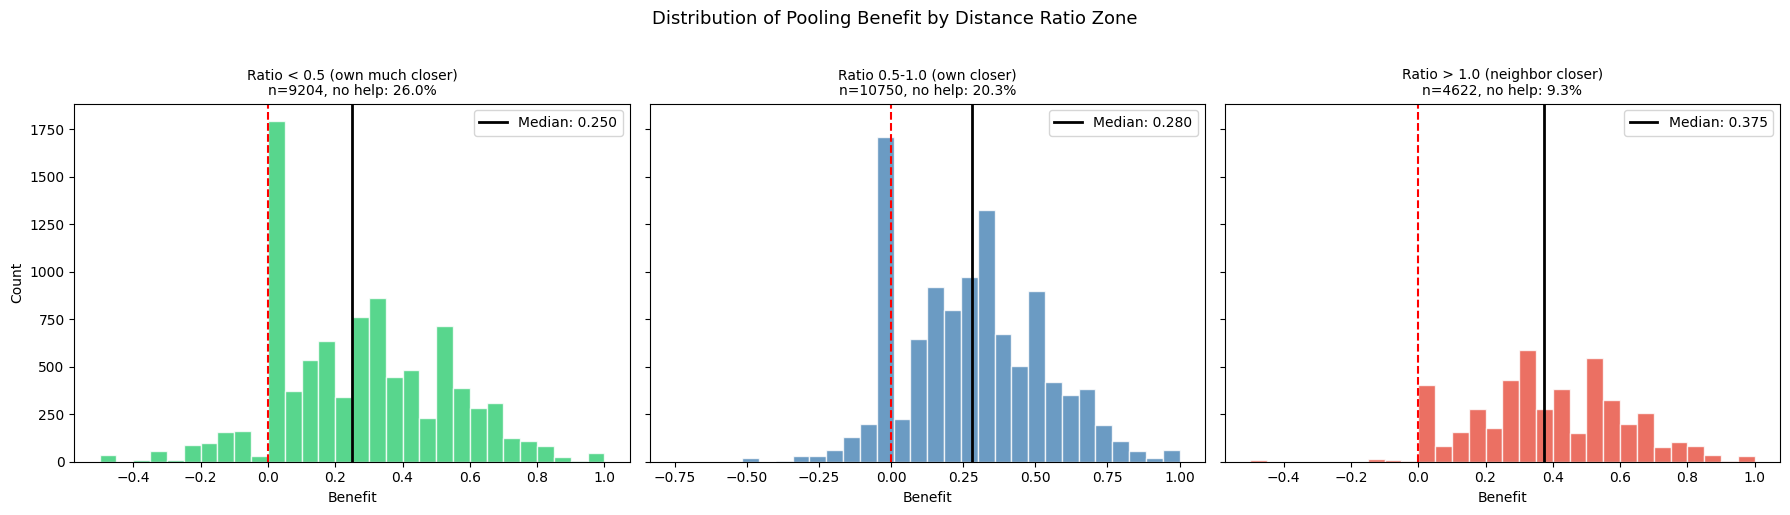

In [6]:
def ratio_zone(r):
    if r < 0.5:
        return "< 0.5 (own much closer)"
    elif r <= 1.0:
        return "0.5-1.0 (own closer)"
    else:
        return "> 1.0 (neighbor closer)"

result["zone"] = [ratio_zone(r) for r in result["distance_ratio"]]

for zone in ["< 0.5 (own much closer)", "0.5-1.0 (own closer)", "> 1.0 (neighbor closer)"]:
    sub = result[result["zone"] == zone]
    b = sub["benefit"]
    print(f"{zone:30s}  n={len(sub):5d}  benefit: median={b.median():.3f}  mean={b.mean():.3f}  no_help={((b <= 0.01).sum()/len(b)):.1%}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
zones = ["< 0.5 (own much closer)", "0.5-1.0 (own closer)", "> 1.0 (neighbor closer)"]
colors = ["#2ecc71", "steelblue", "#e74c3c"]
for ax, zone, color in zip(axes, zones, colors):
    sub = result[result["zone"] == zone]["benefit"]
    ax.hist(sub, bins=30, color=color, alpha=0.8, edgecolor="white")
    ax.axvline(0, color="red", linewidth=1.5, linestyle="--")
    ax.axvline(sub.median(), color="black", linewidth=2, label=f"Median: {sub.median():.3f}")
    ax.set_title(f"Ratio {zone}\nn={len(sub)}, no help: {(sub <= 0.01).mean():.1%}", fontsize=10)
    ax.set_xlabel("Benefit")
    ax.legend()
axes[0].set_ylabel("Count")
fig.suptitle("Distribution of Pooling Benefit by Distance Ratio Zone", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Fraction of Zero Benefit by BCAS Bin (single wave only)

Single-wave scenarios: 4104 / 24576
                               frac_no_benefit        n  bcas_mean
bcas_bin                                                          
(0.009000000000000001, 0.025]            0.254 1026.000      0.018
(0.025, 0.0398]                          0.147 1026.000      0.032
(0.0398, 0.055]                          0.112 1028.000      0.047
(0.055, 0.07]                            0.159 1024.000      0.063


C:\Users\User\AppData\Local\Temp\ipykernel_18832\79919715.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  no_help = single_wave.groupby("bcas_bin", observed=True).apply(


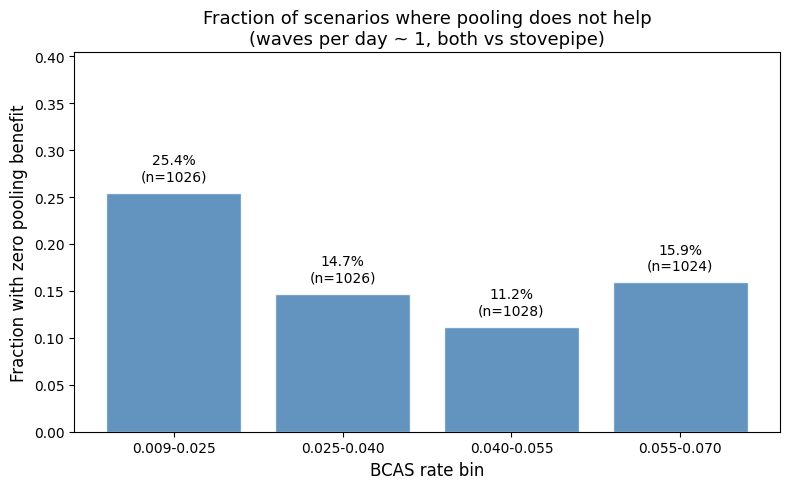

In [7]:
# waves_per_day is continuous (Sobol sampled 1-6), filter for ~1 wave
single_wave = result[result["waves_per_day"] < 1.5].copy()
print(f"Single-wave scenarios: {len(single_wave)} / {len(result)}")

single_wave["bcas_bin"] = pd.qcut(single_wave["bcas_rate"], q=4)
no_help = single_wave.groupby("bcas_bin", observed=True).apply(
    lambda g: pd.Series({
        "frac_no_benefit": (g["benefit"] <= 0.01).mean(),
        "n": len(g),
        "bcas_mean": g["bcas_rate"].mean(),
    })
)
print(no_help.to_string(float_format="%.3f"))

fig, ax = plt.subplots(figsize=(8, 5))
labels = [f"{iv.left:.3f}-{iv.right:.3f}" for iv in no_help.index]
ax.bar(range(len(no_help)), no_help["frac_no_benefit"], color="steelblue", alpha=0.85, edgecolor="white")
for i, (frac, n) in enumerate(zip(no_help["frac_no_benefit"], no_help["n"])):
    ax.text(i, frac + 0.01, f"{frac:.1%}\n(n={int(n)})", ha="center", va="bottom", fontsize=10)
ax.set_xticks(range(len(no_help)))
ax.set_xticklabels(labels, fontsize=10)
ax.set_xlabel("BCAS rate bin", fontsize=12)
ax.set_ylabel("Fraction with zero pooling benefit", fontsize=12)
ax.set_title("Fraction of scenarios where pooling does not help\n(waves per day ~ 1, both vs stovepipe)", fontsize=13)
ax.set_ylim(0, min(1.0, no_help["frac_no_benefit"].max() + 0.15))
plt.tight_layout()
plt.show()